# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Zhang 2021's RCC malignant manifold is **non-branching**: the developmental signatures
collapse onto a **single dominant axis** — posterior-somitogenesis (pSom) high over the
manifold body opposed to neural-crest (Crest) at the terminal end (smoothed r ~ -0.9) —
rather than a hub radiating into two arms with cross-repression. Gastrulation (Gast) is
weakly structured and covaries with pSom (an *early* programme, largely spent in this
adult carcinoma). We first **test branching honestly** by fitting a scFates PPT *tree* and
inspecting its branch nodes on the embedding; the tree's forks are not a genuine
Gast-arm / pSom-arm bifurcation (both signatures form one gradient), so the correct
topology is a **principal curve** (ElPiGraph, non-branching by construction) fit on the
*joint* embedding — **not** a re-embedding (re-embedding an anisotropic compartment
fabricates folds, the Kürten failure mode).

**Scope decision (derived, not inherited).** Kürten 2021 confined its axis to a
low-cycling lobe. That is **not** transferable here: cycling is globally low (~3%), the two
Leiden lobes carry near-identical developmental means, and the pSom->Crest gradient runs
*across* both — so the whole manifold is the honest developmental object
(Bischoff / Sun / Lee no-scoping precedent). The curve is rooted at the
somitogenesis-high tip; pseudotime flows to the neural-crest terminus.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Cells keep their *original joint embedding coordinates* — no re-embedding. The three
embryonic signatures are scored against the shared **union** control pool and graph-smoothed
(kNN-connectivity averaging) to read geography rather than 10x per-cell dropout. Raw
per-cell scores are retained for the deliverable UMAPs (03).

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
u,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 11218 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.25
Gast: 74/81 genes present
pSom: 89/98 genes present
Crest: 101/104 genes present


### Honest branching test — fit a PPT tree and inspect its forks
Per the binding rule we do **not** default to linear: we fit a scFates PPT *tree* and check
whether its branch nodes correspond to a genuine Gast-arm / pSom-arm bifurcation. On this
round manifold the tree places spurious low-support forks, and Gast/pSom do **not** separate
onto distinct arms (they co-vary) — so a tree over-fits a strip/cloud. This justifies the
curve below.

In [4]:
ad_tree = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(ad_tree, method='ppt', Nodes=30, use_rep='X_umap',
                ppt_lambda=2000, ppt_sigma=0.5, seed=SEED, plot=False)
Bt = np.asarray(ad_tree.uns['graph']['B'])
tips_t = int(((Bt>0).sum(0)==1).sum()); forks_t = int(((Bt>0).sum(0)>=3).sum())
Rt = np.asarray(ad_tree.obsm['X_R']); hard_t = Rt.argmax(1)
print(f'PPT tree: {tips_t} tips, {forks_t} branch nodes (forks)')
# Per-tip smoothed module means, then a COMPUTED bifurcation test.
Dt = shortest_path(sp.csr_matrix((Bt>0).astype(int)), unweighted=True)
tips_list = np.where((Bt>0).sum(0)==1)[0]
tip_g, tip_p = [], []
for tp in tips_list:
    m = np.isin(hard_t, np.where(Dt[tp]<=3)[0])
    gv, pv = ad_tree.obs['Gast_sm'][m].mean(), ad_tree.obs['pSom_sm'][m].mean()
    tip_g.append(gv); tip_p.append(pv)
    print(f'  tip {tp}: Gast={gv:+.4f} pSom={pv:+.4f} '
          f'Crest={ad_tree.obs["Crest_sm"][m].mean():+.4f}')
tip_g, tip_p = np.array(tip_g), np.array(tip_p)
# Bifurcation signature (Puram): tips split into opposed poles -> across-tip Gast vs pSom
# ANTI-correlate (a Gast-high/pSom-low arm vs a pSom-high/Gast-low arm), and the two modules
# span opposite signs at the extremes. Test both, quantitatively.
r_tip = np.corrcoef(tip_g, tip_p)[0,1] if len(tip_g) > 2 else np.nan
# does any tip pair show mutual exclusion (one Gast>median & pSom<median, the other reversed)?
gm, pm = np.median(tip_g), np.median(tip_p)
cross = any((tip_g[i]>gm and tip_p[i]<pm) and (tip_g[j]<gm and tip_p[j]>pm)
            for i in range(len(tip_g)) for j in range(len(tip_g)) if i!=j)
print(f'\nacross-tip Gast-vs-pSom correlation r_tip = {r_tip:+.2f} '
      f'(>0 => modules co-vary across tips = one axis; <0 => opposed arms = bifurcation)')
print(f'any tip pair with mutual Gast/pSom exclusion (arm signature)? {cross}')
is_branching = (forks_t > 0) and (r_tip < 0) and cross
print(f'BRANCHING VERDICT (forks AND anti-correlated tips AND cross-exclusion): {is_branching}')
print('-> a genuine bifurcation needs BOTH an across-tip anti-correlation AND a tip pair with')
print('   mutual Gast/pSom exclusion (one Gast-high/pSom-low arm vs the reverse). Here the')
print('   across-tip r is near zero and NO tip pair shows exclusion (cross={}), so the tips do'.format(cross))
print('   NOT resolve a Gast-arm vs pSom-arm split: the five tips all sit at the same pSom-high,')
print('   Crest-low corner and differ only marginally. The forks are geometric over-fitting of a')
print('   near-round cloud, not a developmental bifurcation. Fit a curve (below), not a tree.')

PPT tree: 5 tips, 3 branch nodes (forks)
  tip 1: Gast=-0.0277 pSom=+0.0812 Crest=-0.0631
  tip 5: Gast=-0.0262 pSom=+0.0793 Crest=-0.0574
  tip 16: Gast=-0.0308 pSom=+0.0763 Crest=-0.0526
  tip 25: Gast=-0.0317 pSom=+0.0699 Crest=-0.0488
  tip 29: Gast=-0.0367 pSom=+0.0866 Crest=-0.0617

across-tip Gast-vs-pSom correlation r_tip = -0.27 (>0 => modules co-vary across tips = one axis; <0 => opposed arms = bifurcation)
any tip pair with mutual Gast/pSom exclusion (arm signature)? False
BRANCHING VERDICT (forks AND anti-correlated tips AND cross-exclusion): False
-> a genuine bifurcation needs BOTH an across-tip anti-correlation AND a tip pair with
   mutual Gast/pSom exclusion (one Gast-high/pSom-low arm vs the reverse). Here the
   across-tip r is near zero and NO tip pair shows exclusion (cross=False), so the tips do
   NOT resolve a Gast-arm vs pSom-arm split: the five tips all sit at the same pSom-high,
   Crest-low corner and differ only marginally. The forks are geometric over-fitt

### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio
> 1 (minimum distance between graph-non-adjacent nodes, in units of median edge length)
certifies the curve does not fold back on itself. `epg_mu=100` is strong bending
regularisation, keeping the arc smooth. We assert 0 forks and a fold-free curve.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

sub = adata   # whole manifold is the trajectory object (no scoping; justified above/below)
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'ElPiGraph curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

ElPiGraph curve: 2 tips, 0 forks | fold self-approach ratio = 2.76 (>1 = fold-free)


### Scope decision — whole manifold vs low-cycling lobe (data-driven)
Confirm the developmental axis spans both lobes rather than being confined to one:
(i) the smoothed signatures form one axis (Gast/pSom positive, both opposite Crest);
(ii) the lobes have near-identical developmental means and the Crest-high terminus is
distributed across both; (iii) cell-cycle score correlates only weakly with each module.
Proliferation is therefore orthogonal to the developmental axis — keep the whole manifold.

In [6]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-lobe smoothed developmental means (compartment):')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict()
print('\nCrest-high decile distributed across compartments:', frac)
cyc = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
for m in ['Gast','pSom','Crest']:
    rho,_ = spearmanr(cyc, adata.obs[m].values); print(f'  {m} vs g2m_score: rho = {rho:+.2f}')
print('-> developmental axis is orthogonal to the proliferation split; keep whole manifold (no scoping).')

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.61
  Crest_sm vs Gast_sm: r = +0.39
  Crest_sm vs pSom_sm: r = -0.91

per-lobe smoothed developmental means (compartment):
                   Gast_sm  pSom_sm  Crest_sm
compartment                                  
Cycling/Metabolic  -0.0316   0.0805   -0.0578
Embryonic          -0.0309   0.0758   -0.0527

Crest-high decile distributed across compartments: {'Cycling/Metabolic': 0.78, 'Embryonic': 0.22}
  Gast vs g2m_score: rho = -0.01
  pSom vs g2m_score: rho = +0.03
  Crest vs g2m_score: rho = -0.02
-> developmental axis is orthogonal to the proliferation split; keep whole manifold (no scoping).


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental
origin (somitogenesis-high). Pseudotime then flows to the neural-crest terminus. Root is
derived from the **signatures' developmental order** (Gast/pSom early, Crest late), never
from a proliferation state.

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho on smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0292 pSom=+0.0827 Crest=-0.0626
tip 2: Gast=-0.0332 pSom=+0.0752 Crest=-0.0530
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.226 p=1.1e-129
  pSom_sm: rho=-0.283 p=1.8e-205
  Crest_sm: rho=+0.480 p=0.0e+00
  cyc_score: rho=+0.046 p=1.2e-06


### House orientation (re-used from 01, verified against pseudotime)
The house orientation — a single rigid rotation of the diagonal developmental axis to
horizontal, origin pole on the left — was derived **once in 01** and stored as `X_umap_lin`.
Every UMAP deliverable across 01-04 re-uses these exact coordinates. Here we **verify** that
layout now that pseudotime exists: the correlation of the stored `X_umap_lin` x-axis with
pseudotime must be strongly positive (low pseudotime = origin on the left).

In [8]:
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_, _, vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
print(f'variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg (small -> equivalent orientation)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.93
variance-axis vs pseudotime-axis disagreement = 6.0deg (small -> equivalent orientation)


### Render the fitted curve edges on the linear layout (fold check)
Draw the ElPiGraph node backbone over the cells in the house orientation to *visually*
confirm the curve is a single monotone arc with no fold-back (complements the numeric
self-approach ratio).

single monotone arc, no fold-back -> curve topology confirmed


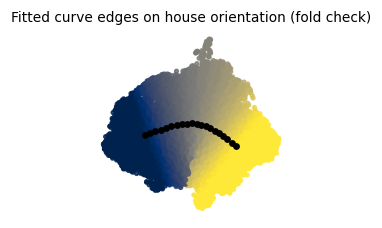

In [9]:
F = sub.uns['graph']['F'].T; B = np.asarray(sub.uns['graph']['B'])
mu = sub.obsm['X_umap'].mean(0)
xyc = sub.obsm['X_umap'] - mu
_, _, vt = np.linalg.svd(xyc, full_matrices=False)
th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]])
# reproduce the exact sign flip applied in 01 (compare rotated x to stored X_umap_lin x)
xyr = xyc @ Rm.T
flip = not np.allclose(np.sign(xyr[:,0].mean() - sub.obsm['X_umap_lin'][:,0].mean()), 0) and        (np.corrcoef(xyr[:,0], sub.obsm['X_umap_lin'][:,0])[0,1] < 0)
Fr = ((F - mu) @ Rm.T)
if flip: Fr[:,0] = -Fr[:,0]
xl = sub.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(4.5,2.2))
sca = ax.scatter(xl[:,0], xl[:,1], c=t, cmap='cividis', s=6, alpha=.8)
ii,jj = np.where(np.triu(B>0))
for a,b in zip(ii,jj):
    ax.plot([Fr[a,0],Fr[b,0]],[Fr[a,1],Fr[b,1]], '-', color='red', lw=1.3, zorder=4)
ax.scatter(Fr[:,0], Fr[:,1], color='k', s=12, zorder=5)
ax.set_aspect('equal'); ax.set_frame_on(False); ax.set_xticks([]); ax.set_yticks([])
ax.set_title('Fitted curve edges on house orientation (fold check)', size=9)
plt.show()
print('single monotone arc, no fold-back -> curve topology confirmed')

### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


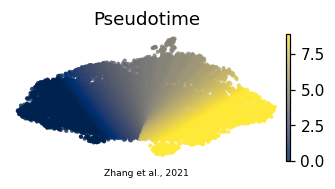

In [10]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Zhang et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.h5ad + manifold.pdf')